In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [13]:
#--- STEP 1: GPU CHECK ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Targeting device: {device}")
if device.type == 'cuda':
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

Targeting device: cuda
GPU Name: NVIDIA GeForce RTX 3050 Laptop GPU


In [15]:
# --- STEP 2: CUSTOM DATASET CLASS ---
class CricketDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

In [17]:
# --- STEP 3: PATHS & SPLITTING ---
data_dir = r'C:\Users\DELL\Downloads\dataset\data' # Ensure this points to the folder containing 'drive', 'pullshot', etc.
class_names = ['drive', 'legglance-flick', 'pullshot', 'sweep']
image_paths = []
labels = []

for idx, class_name in enumerate(class_names):
    class_dir = os.path.join(data_dir, class_name)
    if not os.path.exists(class_dir): continue
    for img_file in os.listdir(class_dir):
        if img_file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            image_paths.append(os.path.join(class_dir, img_file))
            labels.append(idx)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels, test_size=0.2, stratify=labels, random_state=42
)

In [19]:
# --- STEP 4: TRANSFORM & LOADERS ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_loader = DataLoader(CricketDataset(train_paths, train_labels, transform), batch_size=32, shuffle=True)
val_loader = DataLoader(CricketDataset(val_paths, val_labels, transform), batch_size=32, shuffle=False)

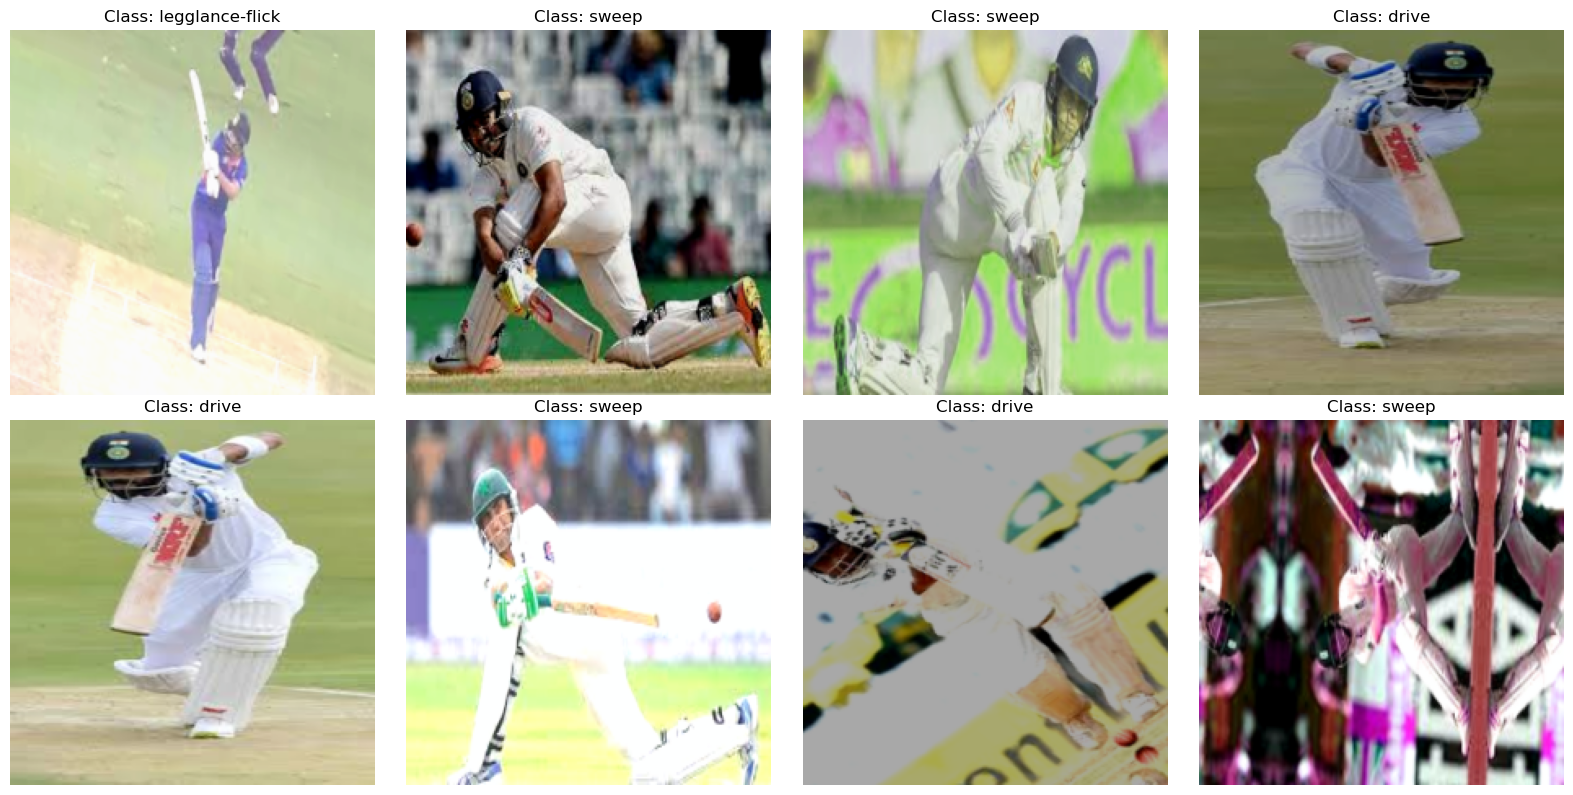

In [35]:
import numpy as np
import matplotlib.pyplot as plt

def show_batch(sample_batch):
    """Visualizes a batch of images from the dataloader."""
    images, labels = sample_batch
    
    # Create a grid
    plt.figure(figsize=(16, 8))
    
    # Show up to 8 images from the batch
    for i in range(min(8, len(images))):
        ax = plt.subplot(2, 4, i + 1)
        
        # Un-normalize the image for display
        # (ResNet normalization: img = (tensor * std) + mean)
        img = images[i].numpy().transpose((1, 2, 0))
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        
        plt.imshow(img)
        plt.title(f"Class: {class_names[labels[i]]}")
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

# Get one batch of training images
example_batch = next(iter(train_loader))
show_batch(example_batch)

In [21]:
# --- STEP 5: MODEL (ResNet50) ---
model = models.resnet50(weights='IMAGENET1K_V2')
for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Sequential(
    nn.Linear(model.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(512, len(class_names))
)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\DELL/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|█████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [00:16<00:00, 6.21MB/s]


In [23]:
# --- STEP 6: TRAINING LOOP ---
epochs = 10
history = {'train_acc': [], 'val_acc': []}

for epoch in range(epochs):
    model.train()
    correct, total = 0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()
        correct += (outputs.argmax(1) == lbls).sum().item()
        total += lbls.size(0)
    
    train_acc = correct / total
    
    # Validation
    model.eval()
    val_correct, val_total = 0, 0
    all_preds, all_lbls = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1)
            val_correct += (preds == lbls).sum().item()
            val_total += lbls.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_lbls.extend(lbls.cpu().numpy())
            
    val_acc = val_correct / val_total
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}: Train Acc {train_acc:.4f} | Val Acc {val_acc:.4f}")

Epoch 1: Train Acc 0.7634 | Val Acc 0.9259
Epoch 2: Train Acc 0.9500 | Val Acc 0.9714
Epoch 3: Train Acc 0.9627 | Val Acc 0.9757
Epoch 4: Train Acc 0.9764 | Val Acc 0.9746
Epoch 5: Train Acc 0.9788 | Val Acc 0.9820
Epoch 6: Train Acc 0.9889 | Val Acc 0.9619
Epoch 7: Train Acc 0.9849 | Val Acc 0.9746
Epoch 8: Train Acc 0.9860 | Val Acc 0.9672
Epoch 9: Train Acc 0.9746 | Val Acc 0.9820
Epoch 10: Train Acc 0.9878 | Val Acc 0.9746


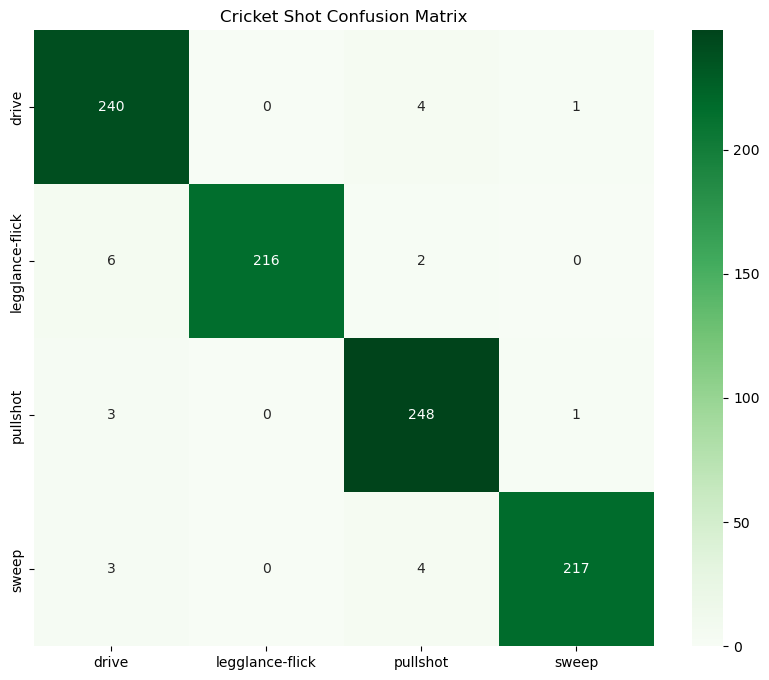

                 precision    recall  f1-score   support

          drive       0.95      0.98      0.97       245
legglance-flick       1.00      0.96      0.98       224
       pullshot       0.96      0.98      0.97       252
          sweep       0.99      0.97      0.98       224

       accuracy                           0.97       945
      macro avg       0.98      0.97      0.97       945
   weighted avg       0.98      0.97      0.97       945



In [27]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(all_lbls, all_preds)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Greens')
plt.title('Cricket Shot Confusion Matrix')
plt.show()

print(classification_report(all_lbls, all_preds, target_names=class_names))

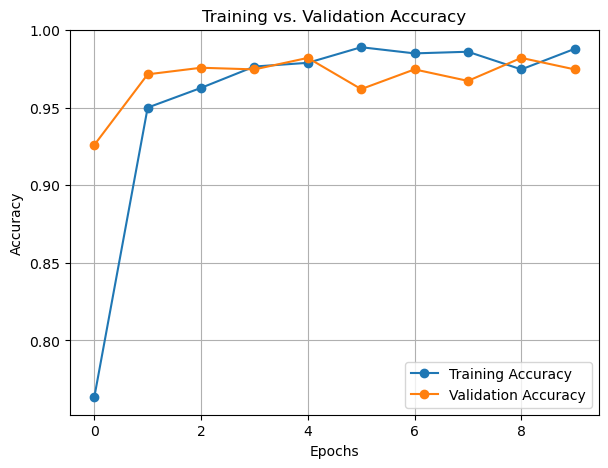

In [29]:
# Create a figure for Accuracy and Loss
plt.figure(figsize=(15, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history['train_acc'], label='Training Accuracy', marker='o')
plt.plot(history['val_acc'], label='Validation Accuracy', marker='o')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Note: If you tracked loss in your loop, plot it here
# plt.subplot(1, 2, 2)
# plt.plot(history['train_loss'], label='Training Loss')
# ...

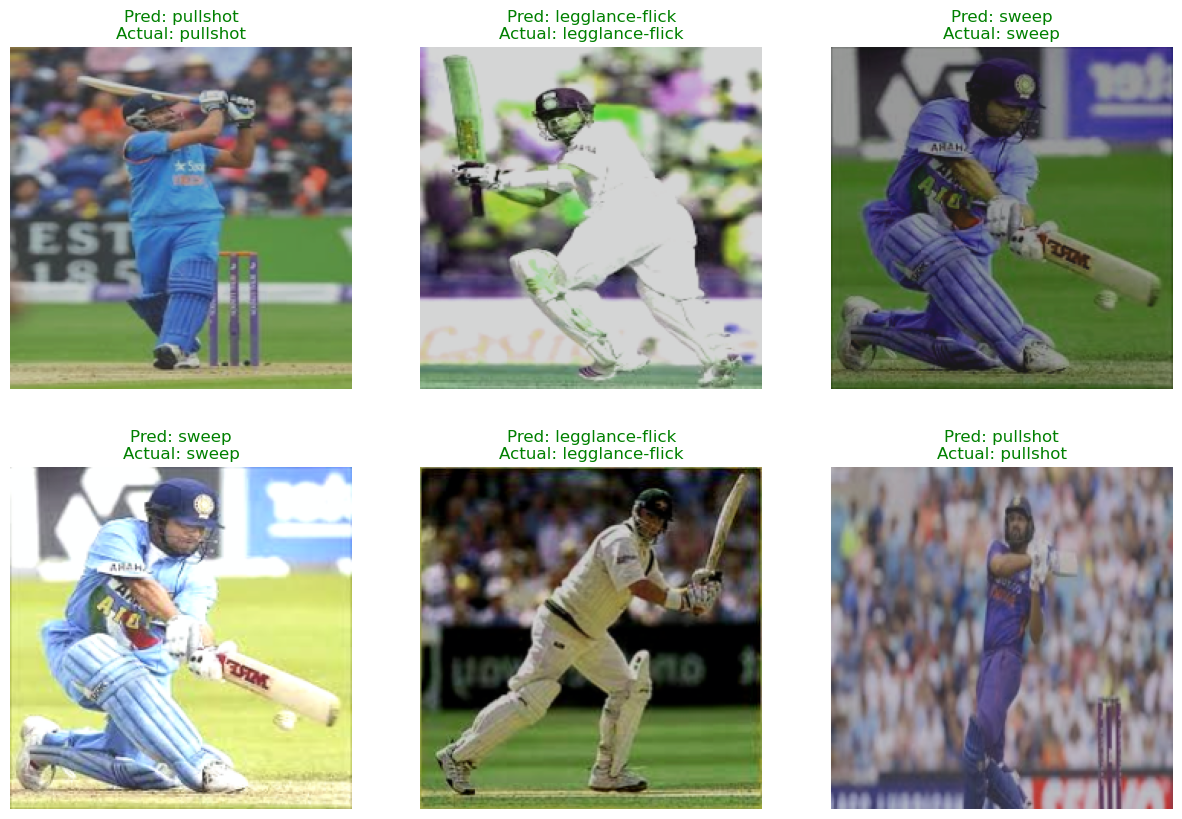

In [31]:
def visualize_model_predictions(model, loader, num_images=6):
    model.eval()
    images_so_far = 0
    plt.figure(figsize=(15, 10))

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(loader):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images // 3, 3, images_so_far)
                ax.axis('off')
                
                # Un-normalize image for display
                img = inputs.cpu().data[j].numpy().transpose((1, 2, 0))
                mean = np.array([0.485, 0.456, 0.406])
                std = np.array([0.229, 0.224, 0.225])
                img = std * img + mean
                img = np.clip(img, 0, 1)
                
                color = 'green' if preds[j] == labels[j] else 'red'
                ax.set_title(f'Pred: {class_names[preds[j]]}\nActual: {class_names[labels[j]]}', color=color)
                plt.imshow(img)

                if images_so_far == num_images:
                    return

visualize_model_predictions(model, val_loader)

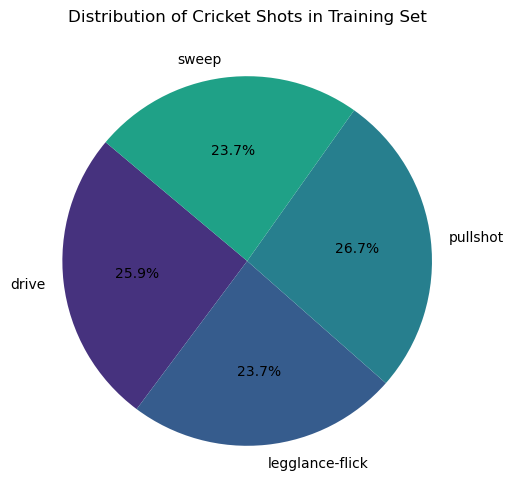

In [33]:
# Count samples per class in the split
from collections import Counter
train_counts = Counter(train_labels)

plt.figure(figsize=(8, 6))
plt.pie([train_counts[i] for i in range(len(class_names))], 
        labels=class_names, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('viridis'))
plt.title('Distribution of Cricket Shots in Training Set')
plt.show()